# 小さな分子で学ぶ位相推定
## H₂/STO-3G・Parity変換：系1量子ビットで S₀–S₂ を測る

「小さな行列で学ぶ位相推定」の姉妹編です。節0〜10、記号、**予想 → 実行 → 数式と照合 → 演習**を揃えています。
逆QFT型QPE、系を保持するiterative QPE、毎ショット再準備するBPE、Fig. 1B型BPDE、Fig. 1C型の全0測定を比較します。

分子はH₂、核間距離0.735 Å、STO-3G、全2電子・全2空間軌道。分子全体の一重項をエネルギー順にS₀,S₁,S₂と呼び、
**同じ不変部分空間のS₀とS₂**を対象にします。S₁や最低三重項はこの1量子ビットに含みません。
論理系1個に加え、QPEは補助m個、IQPE/BPE/BPDEは補助1個を使います。

### 学習目標
1. 分子の電子配置、固有状態、量子ビットの状態を対応させる。
2. 物理的時間発展の負符号、位相の周期、エネルギーへの換算を説明する。
3. HFと厳密状態を使い分け、分解能・shot誤差・状態準備とモデルの不一致を区別する。
4. エネルギー差の直接推定と全0測定の意味を確認する。

本編は2〜3回に分けて進められます。複素数、内積、2×2行列、量子回路の基本を前提とします。
本編は固定行列を内蔵し、NumPy/Matplotlib/Qiskit/pylatexencで単体実行できます。
付録Aの再生成のみPySCFが必要です。全セルを実行する場合はPySCFもインストールしてください。
IBMアカウント、QPU、Aer、他のリポジトリファイルは不要です。shot/countはすべて模擬測定です。

BPE/BPDEは固定設定の教育用グリッドベイズ法で、原著の適応的更新、Gaussian近似、MPO圧縮の再現ではありません。
厳密対角化は小分子で答え合わせと準備回路を作るために使い、量子優位性を示すものではありません。

In [1]:
# 必要ならコメントを外し、インストール後にカーネルを再起動してください。
# %pip install "numpy>=1.26,<3" "matplotlib>=3.8,<4" "qiskit>=2,<3" "pylatexenc>=2.10,<3" "pyscf>=2.7,<3"

In [2]:
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import qiskit
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Statevector, Operator, DensityMatrix
from IPython.display import display
np.set_printoptions(precision=8, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
TAU = 2*np.pi
ATOL = 1e-10

def draw(qc, fold=110):
    # 回路を画像で表示。数値計算にはこの描画関数は使わない。
    fig = qc.draw(output="mpl", fold=fold)
    display(fig)
    plt.close(fig)

def draw_measured(qc, qubits):
    # 描画用のコピーだけに測定を追加。厳密確率は測定前の回路から計算する。
    measured = qc.copy()
    readout = ClassicalRegister(len(qubits), "readout")
    measured.add_register(readout)
    measured.measure(qubits, readout)
    draw(measured)

def show_probs(probabilities, title, ax=None, shots=None, seed=123):
    p = np.asarray(probabilities, dtype=float)
    m = int(np.log2(len(p)))
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 3))
    x = np.arange(len(p))
    ax.bar(x, p, width=0.65, label="Exact probability", alpha=0.75)
    if shots:
        counts = np.random.default_rng(seed).multinomial(shots, p / p.sum())
        ax.plot(x, counts / shots, "ko", ms=4, label=f"{shots} simulated shots")
    ax.set_xticks(x, [format(i, f"0{m}b") for i in x], rotation=60 if m > 3 else 0)
    ax.set(xlabel="Measured bits (MSB ... LSB)", ylabel="Probability", title=title)
    ax.legend(fontsize=8)
    return ax


print("Python", sys.version.split()[0], "NumPy", np.__version__, "Qiskit", qiskit.__version__)

Python 3.12.7 NumPy 2.4.6 Qiskit 2.4.1


## 0．共通の行列とビット順序：H₂を1量子ビットで表す

スピン軌道は $(\alpha0,\alpha1,\beta0,\beta1)$ の順です。Parityビットは
$p_j=(n_0+\cdots+n_j)\bmod2$。$N_\alpha=N_\beta=1$では$p_1=1,p_3=0$を固定でき、
残る2ビットを $|p_2p_0\rangle$ と表示します。この2量子ビット行列から
$\{|01\rangle,|10\rangle\}$を取り出し、
$$|0\rangle_{\rm L}=|01\rangle_{\rm parity},\quad
|1\rangle_{\rm L}=|10\rangle_{\rm parity}$$
と符号化します。前者はHF配置、後者は両電子を反結合性軌道へ移した二重励起配置です。
時間発展で外へ出ない**不変部分空間**の正確な符号化であり、量子ビットを単に捨てる操作ではありません。

$$H_{\rm el}=\begin{pmatrix}-1.8369679912&0.1809311998\\0.1809311998&-0.2452182918\end{pmatrix}
=cI-zZ+xX.$$
核間反発$E_{\rm nuc}=0.7199689944$ Hartreeを加えると全エネルギーです。
以下の演算子$H$は**電子**ハミルトニアン。原子単位系で$\hbar=1$、時間は原子単位、エネルギーはHartreeです。

### 位相の符号と周期
$$U=e^{-iH\Delta t},\quad \Delta t=1,\qquad
\phi_j=-E_j^{\rm el}\Delta t/(2\pi)\pmod1.$$
既知の探索区間を$-2<E^{\rm el}<0$ Hartreeとします。この区間では
$E^{\rm el}=-2\pi\phi/\Delta t$を使えます。答えを二進数格子へ合わせる調整はしません。
ギャップは$0<\Delta E<2$とし、
$$\delta\phi=\phi_{S_2}-\phi_{S_0}<0,\quad
\Delta=\delta\phi\bmod1,\quad
\Delta E=\frac{2\pi(1-\Delta)}{\Delta t}.$$
負の位相差を$[0,1)$で表すため、正のエネルギー差に戻すときは$1-\Delta$を使います。
この換算は選んだ探索区間に依存します。

Qiskitの状態ベクトルは$|q_{n-1}\cdots q_0\rangle$順。
QPEでは補助$q_0,\ldots,q_{m-1}$、系$q_m$。補助出力整数$y$は位相$y/2^m$。
2ビット回路では$q_0=a$（補助）、$q_1=s$（系）。数式の$|a,s\rangle$に対し配列添字は$2s+a$です。

H electronic =
 [[-1.83696799  0.1809312 ]
 [ 0.1809312  -0.24521829]]
S0,S2 total energies: [-1.13730604  0.49505774]
S0,S2 phases: [0.2955945  0.03579574] phase gap modulo 1: 0.7402012359071664
S2-S0 gap (Hartree): 1.6323637773715078
HF total expectation: -1.1169989967540044 HF eigenstate weights: [0.98755973 0.01244027]
theta: -0.22353699826765971


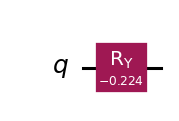

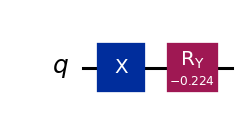

In [3]:
H = np.array([[-1.836967991202984, 0.18093119978423136],
              [0.18093119978423136, -0.24521829183026772]])
ENUC = 0.7199689944489797
DT = 1.0
c = np.trace(H)/2
z = (H[1,1]-H[0,0])/2
x = H[0,1]
rho_h = np.hypot(z,x)
theta = -np.arctan2(x,z)
def ry(angle):
    co, si = np.cos(angle/2), np.sin(angle/2)
    return np.array([[co,-si],[si,co]], complex)
R = ry(theta)
E = np.array([c-rho_h, c+rho_h])
PHASES = -E*DT/TAU
GAP = (PHASES[1]-PHASES[0]) % 1
ENERGY_GAP = E[1]-E[0]
zero = np.array([1,0], complex)  # 論理HF配置。固有状態ではない。
one = np.array([0,1], complex)
g, e = R[:,0], R[:,1]
psi_mixed = np.sqrt(.75)*g + np.sqrt(.25)*e
HF_WEIGHTS = abs(R.conj().T @ zero)**2

def u_power(L, phases=PHASES):
    return R @ np.diag(np.exp(1j*TAU*L*np.asarray(phases))) @ R.conj().T

def phase_to_total(phi): return -TAU*np.asarray(phi)/DT + ENUC
def phase_to_gap(delta): return TAU*(1-np.asarray(delta))/DT
assert np.allclose(R.T@H@R, np.diag(E), atol=ATOL)
assert np.allclose(phase_to_total(PHASES), E+ENUC)
assert np.isclose(phase_to_gap(GAP), ENERGY_GAP)
print("H electronic =\n", H)
print("S0,S2 total energies:", E+ENUC)
print("S0,S2 phases:", PHASES, "phase gap modulo 1:", GAP)
print("S2-S0 gap (Hartree):", ENERGY_GAP)
print("HF total expectation:", H[0,0]+ENUC, "HF eigenstate weights:", HF_WEIGHTS)
print("theta:", theta)
prep_g = QuantumCircuit(1); prep_g.ry(theta,0)
prep_e = QuantumCircuit(1); prep_e.x(0); prep_e.ry(theta,0)
draw(prep_g); draw(prep_e)

### 0.1 桁番号・反復回数・時間

| 記号 | 意味 |
|---|---|
| $m$ | 読み取る位相の二進数桁数 |
| $b_j$ | 小数点から数えた第$j$桁 |
| $r$ | べき$2^r$の指数、$0,\ldots,m-1$ |
| $L$ | 基本操作$U$の反復回数。桁番号ではない |
| $\Delta t$ | $U$一回の基本時間、本編では1原子単位 |
| $t=L\Delta t$ | 1ショットの発展時間 |
| $\Delta$ | 位相差を$[0,1)$で表した値 |
| $\Delta E$ | 正のS₂–S₀エネルギー差 |

QPEは$L=2^r$。IQPEは$m=3$なら$L=4,2,1$と選び、下位ビットから読みます。
BPE/BPDEの$L$は感度を選ぶ実験設定で、2のべきに限りません。

**演習0：** HFはなぜ固有状態でないか。$U^5$は位相の第5桁の測定か。
<details><summary>解答例</summary>
$H|0\rangle$は非零の$|1\rangle$成分を持ちます。$U^5$は$t=5\Delta t$の発展であり、第5桁を直接指定しません。
</details>

## 1．共通部品：分子の時間発展を干渉で読む

厳密状態では$U^L|S_j\rangle=e^{-iE_jt}|S_j\rangle$。
補助H → 制御$U^L$ → $P(\beta)$ → Hにより
$$P(a=0)=\frac{1+\cos(2\pi L\phi_j+\beta)}2
=\frac{1+\cos(E_jt-\beta)}2.$$
位相候補$\epsilon$に$\beta=-2\pi L\epsilon$を設定します。
エネルギー候補$\varepsilon$なら$\beta=\varepsilon t$です。

**予想：** 時間を長くするとピークはいくつになるでしょうか。

時間発展は厳密に
$$U^L=e^{-ict}R_y(\theta)R_z(-2\rho t)R_y(-\theta),\quad \rho=\sqrt{x^2+z^2}$$
と実装できます。Qiskitの時間順は右端の回転からです。制御付きでは$e^{-ict}$も保持します。

Constant kept: 0.35871190082516224 omitted: 0.8425039119871764


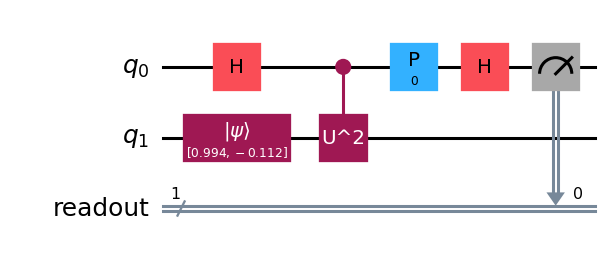

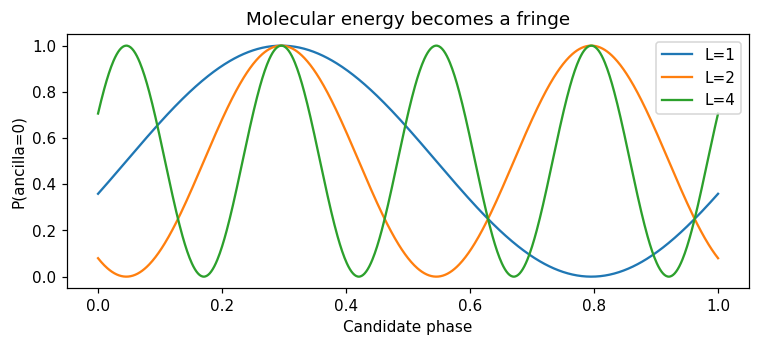

In [4]:
def evolution_gate(L, keep_constant=True):
    t = L*DT
    qc = QuantumCircuit(1, name=f"U^{L}")
    qc.ry(-theta,0); qc.rz(-2*rho_h*t,0); qc.ry(theta,0)
    if keep_constant: qc.global_phase = -c*t
    return qc.to_gate()

def ramsey_circuit(psi, L=1, beta=0., keep_constant=True):
    qc = QuantumCircuit(2)
    qc.initialize(psi,1); qc.h(0)
    qc.append(evolution_gate(L,keep_constant).control(), [0,1])
    qc.p(beta,0); qc.h(0)
    return qc

def ancilla_zero(qc):
    return float(Statevector.from_instruction(qc).probabilities([0])[0])

def bpe_probability(weights,L,beta):
    amp = np.dot(weights,np.exp(1j*TAU*L*PHASES))
    return .5*(1+np.real(np.exp(1j*beta)*amp))

for L in [1,2,5,32]:
    assert np.allclose(Operator(evolution_gate(L)).data,u_power(L),atol=ATOL)
draw_measured(ramsey_circuit(g,2),[0])
candidates = np.linspace(0,1,801)
fig,ax = plt.subplots(figsize=(8,3))
for L in [1,2,4]:
    ax.plot(candidates,bpe_probability([1,0],L,-TAU*L*candidates),label=f"L={L}")
    for beta in [0,.37,-1.2]:
        assert np.isclose(ancilla_zero(ramsey_circuit(g,L,beta)),bpe_probability([1,0],L,beta),atol=ATOL)
ax.set(xlabel="Candidate phase",ylabel="P(ancilla=0)",title="Molecular energy becomes a fringe")
ax.legend(); plt.show()
print("Constant kept:",ancilla_zero(ramsey_circuit(g)),"omitted:",ancilla_zero(ramsey_circuit(g,keep_constant=False)))
assert not np.isclose(ancilla_zero(ramsey_circuit(g)),ancilla_zero(ramsey_circuit(g,keep_constant=False)))

### 演習1：全体位相は捨ててよいか？

1. 候補位相を$1/L$増やしても信号が変わらないことを示してください。
2. なぜ制御Uでは$cI$を省略できませんか。
<details><summary>解答例</summary>
余弦の引数が$2\pi$増えるからです。制御Uの$e^{-ict}$は補助の1の枝だけに作用し、相対位相になります。
系だけの時間発展では全体位相でも、制御した全回路では全体位相ではありません。
</details>

## 2．逆QFT型QPE：分子エネルギーを補助ビットへ

$$P(y\mid\phi)=\left|\frac1{2^m}\sum_{k=0}^{2^m-1}
 e^{2\pi ik(\phi-y/2^m)}\right|^2.$$
元教材の特別な三桁位相と違い、分子の位相は有限二進数で正確に表せません。
厳密固有状態でも複数のビット列が出ます。入力が$\sum_j c_j|S_j\rangle$なら
$P(y)=\sum_j|c_j|^2P(y\mid\phi_j)$です。

**予想：** HFを入力すると、HFの期待エネルギーが一つ出ますか。

HF weights S0,S2: [0.98755973 0.01244027]
Finite-m output energies are grid estimates, not the HF expectation.


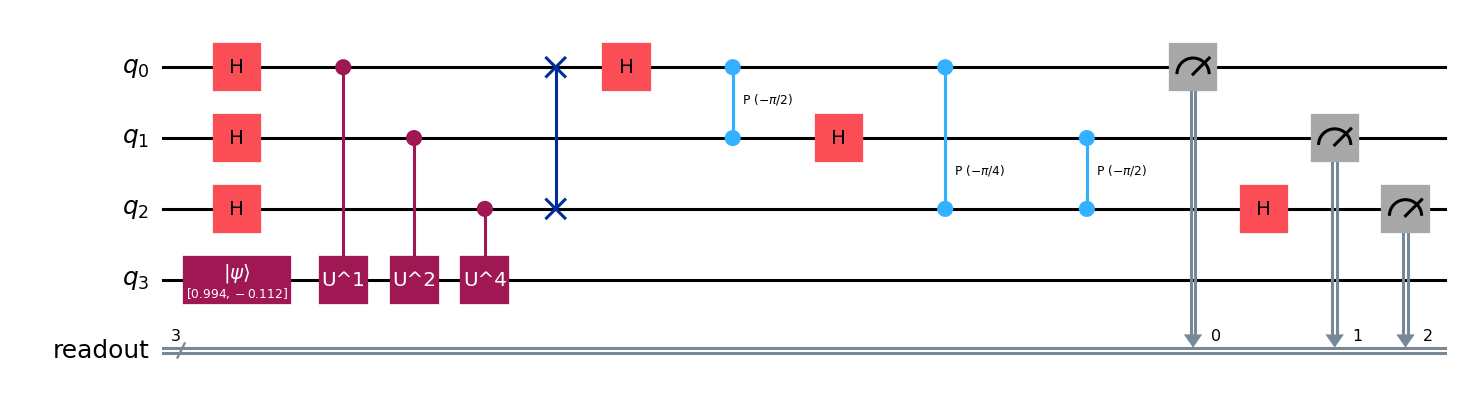

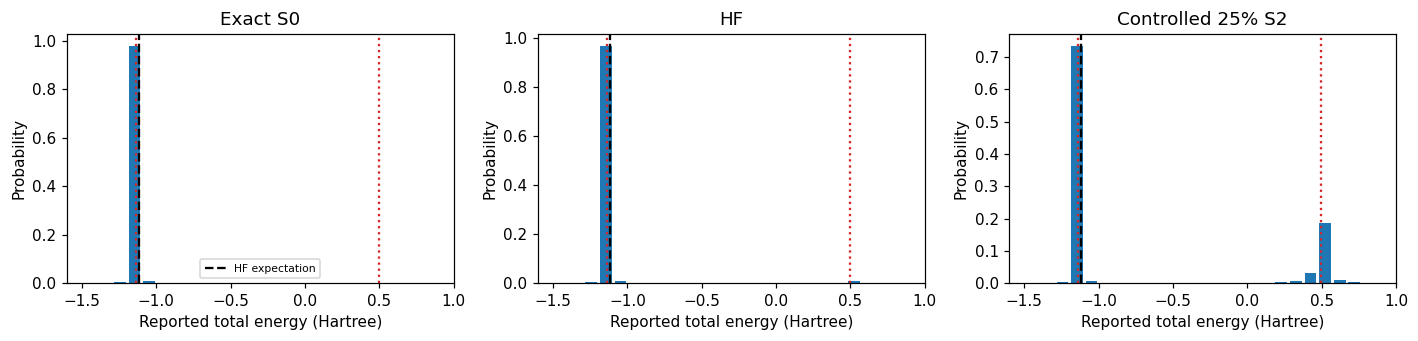

In [5]:
def inverse_qft(m):
    qc = QuantumCircuit(m, name="QFT_dg")
    for j in range(m // 2):
        qc.swap(j, m - 1 - j)
    for j in range(m):
        for ell in range(j):
            qc.cp(-np.pi / 2**(j - ell), j, ell)
        qc.h(j)
    return qc

def qpe_circuit(psi, m=3, phases=PHASES):
    qc = QuantumCircuit(m + 1)
    qc.initialize(psi, m)
    for r in range(m):
        qc.h(r)
        qc.append(UnitaryGate(u_power(2**r, phases), label=f"U^{2**r}").control(), [r, m])
    qc.compose(inverse_qft(m), list(range(m)), inplace=True)
    return qc

def qpe_distribution(psi, m=3, phases=PHASES):
    state = Statevector.from_instruction(qpe_circuit(psi, m, phases))
    return state.probabilities(list(range(m)))


def qpe_formula(phi,m):
    M=2**m
    amp=np.mean(np.exp(1j*TAU*np.outer(np.arange(M),phi-np.arange(M)/M)),axis=0)
    return abs(amp)**2
M=8; xx=np.arange(M)
assert np.allclose(Operator(inverse_qft(3)).data,np.exp(-1j*TAU*np.outer(xx,xx)/M)/np.sqrt(M),atol=ATOL)
draw_measured(qpe_circuit(g,m=3),[0,1,2])
fig,axes=plt.subplots(1,3,figsize=(13,3.2))
for ax,state,label in zip(axes,[g,zero,psi_mixed],["Exact S0","HF","Controlled 25% S2"]):
    p=qpe_distribution(state,m=6)
    w=abs(R.T@state)**2
    expected=sum(wj*qpe_formula(phi,6) for wj,phi in zip(w,PHASES))
    assert np.allclose(p,expected,atol=ATOL)
    # 候補エネルギーも表示し、負符号を実際に換算する。
    energies=phase_to_total(np.arange(64)/64)
    ax.bar(energies,p,width=TAU/64*.8)
    for Ej in E+ENUC: ax.axvline(Ej,color="C3",ls=":")
    ax.axvline(H[0,0]+ENUC,color="black",ls="--",label="HF expectation")
    ax.set(xlim=(-1.6,1),xlabel="Reported total energy (Hartree)",ylabel="Probability",title=label)
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()
p_qpe=qpe_distribution(psi_mixed,m=3)
print("HF weights S0,S2:",HF_WEIGHTS)
print("Finite-m output energies are grid estimates, not the HF expectation.")

### 演習2：HFエネルギーとQPEの出力

HFのQPEで基底状態を得る確率はなぜ約98.76%か。残りはS₁か。
<details><summary>解答例</summary>
$|\langle S_0|HF\rangle|^2$で決まり、残り約1.24%はこの空間のS₂です。
十分な分解能での成分の重みを指し、有限mの特定ビット列がその確率になるという意味ではありません。
S₁は元の4×4行列の別ブロックにあり、本編の1量子ビットには入りません。
</details>

## 3．iterative QPE：補助1個でも系を保持する

$m=3$なら$L=4,2,1$の順に下位ビットから読みます。
既読の整数$y_{\rm known}$に対し$\beta=-2\pi L y_{\rm known}/2^m$。
測定$b$のKraus演算子は
$$M_b=\frac{I+(-1)^be^{i\beta}U^L}{2},\quad
p_b=\|M_b\psi\|^2,\quad |\psi_b\rangle=M_b|\psi\rangle/\sqrt{p_b}.$$
補助はリセットしても**系は条件付き状態を保持**します。
動的回路を描画し、数値は全分岐をKraus式で計算します。

**予想：** 各ビットの前に同じ近似状態を再準備しても同じ分布になりますか。

round L history(time order) branch probability eigenstate weights(S0,S2)
(1, 4, '0', 0.7323158124426197, array([0.72315769, 0.27684231]))
(1, 4, '1', 0.2676841875573804, array([0.82343373, 0.17656627]))
(2, 2, '00', 0.23493892806720906, array([0.17998968, 0.82001032]))
(2, 2, '01', 0.4973768843754106, array([0.97972633, 0.02027367]))
(2, 2, '10', 0.08437037795351615, array([0.59811335, 0.40188665]))
(2, 2, '11', 0.18331380960386426, array([0.92713767, 0.07286233]))
(3, 1, '000', 0.20539496629619902, array([0.07385137, 0.92614863]))
(3, 1, '001', 0.029543961771010065, array([0.91788236, 0.08211764]))
(3, 1, '010', 0.48352963194618825, array([0.98724741, 0.01275259]))
(3, 1, '011', 0.01384725242922266, array([0.71709916, 0.28290084]))


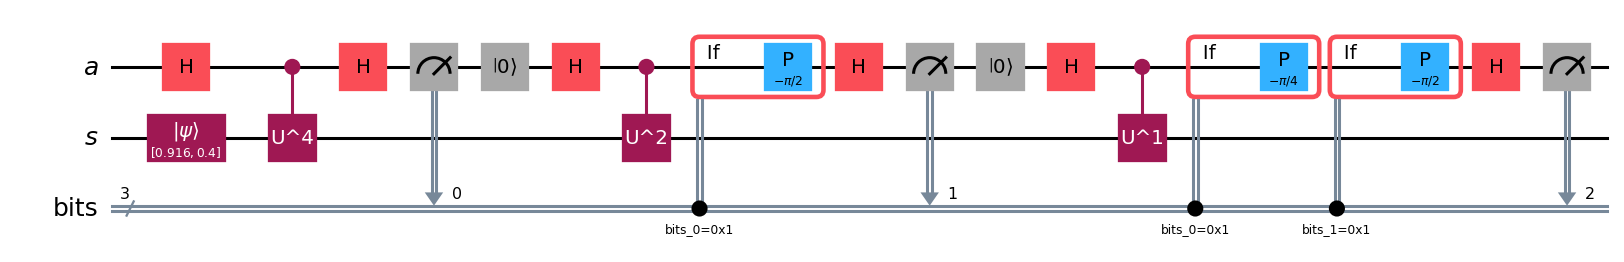

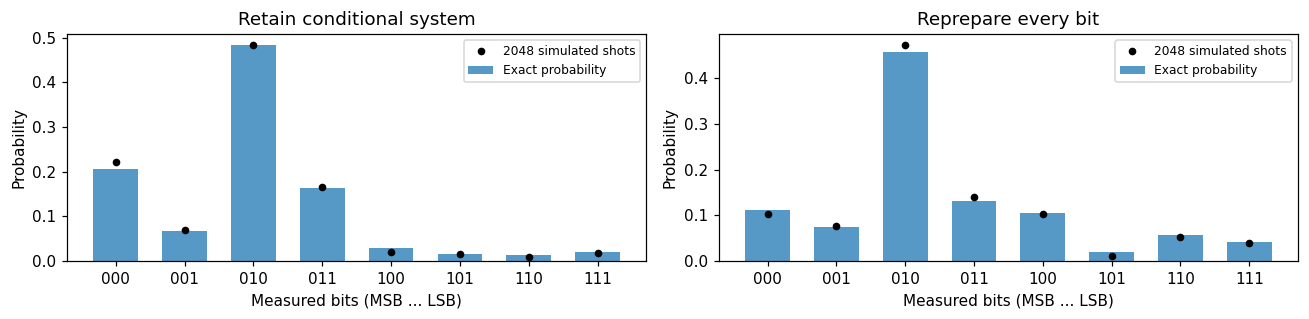

In [6]:
def iqpe_dynamic_circuit(m=3):
    a = QuantumRegister(1, "a")
    s = QuantumRegister(1, "s")
    c = ClassicalRegister(m, "bits")
    qc = QuantumCircuit(a, s, c)
    qc.initialize(psi_mixed, s[0])
    for ell, r in enumerate(reversed(range(m))):
        L = 2**r
        if ell:
            qc.reset(a[0])
        qc.h(a[0])
        qc.append(UnitaryGate(u_power(L), label=f"U^{L}").control(), [a[0], s[0]])
        for old in range(ell):
            angle = -TAU * L * 2**old / 2**m
            with qc.if_test((c[old], 1)):
                qc.p(angle, a[0])
        qc.h(a[0])
        qc.measure(a[0], c[ell])
    return qc

def iqpe_tree(psi, m=3, phases=PHASES, reprepare=False):
    # (既知の整数, 分岐確率, 条件付き系状態, 測定履歴)
    branches = [(0, 1.0, np.array(psi, complex), "")]
    trace = []
    for ell, r in enumerate(reversed(range(m))):
        next_branches = []
        L = 2**r
        for y, weight, conditional, history in branches:
            incoming = np.array(psi, complex) if reprepare else conditional
            beta = -TAU * L * y / 2**m
            for b in [0, 1]:
                out = (incoming + (-1)**b * np.exp(1j*beta) * (u_power(L, phases) @ incoming)) / 2
                probability = float(np.vdot(out, out).real)
                if probability < 1e-14:
                    continue
                state = out / np.sqrt(probability)
                new_y = y + b * 2**ell
                new_history = history + str(b)  # 時間順。最終表示のビット順とは逆。
                next_branches.append((new_y, weight*probability, state, new_history))
                trace.append((ell+1, L, new_history, weight*probability, abs(R.conj().T @ state)**2))
        branches = next_branches
    distribution = np.zeros(2**m)
    for y, weight, _, _ in branches:
        distribution[y] += weight
    return distribution, trace


draw(iqpe_dynamic_circuit(m=3),fold=95)
p_iqpe,trace=iqpe_tree(psi_mixed,m=3)
p_reset,_=iqpe_tree(psi_mixed,m=3,reprepare=True)
assert np.allclose(p_iqpe,p_qpe,atol=ATOL)
assert not np.allclose(p_reset,p_qpe,atol=ATOL)
fig,axes=plt.subplots(1,2,figsize=(12,3))
show_probs(p_iqpe,"Retain conditional system",axes[0],shots=2048)
show_probs(p_reset,"Reprepare every bit",axes[1],shots=2048)
plt.tight_layout(); plt.show()
print("round L history(time order) branch probability eigenstate weights(S0,S2)")
for row in trace[:10]: print(row)
for m in [2,3,6]:
    for state in [g,zero,psi_mixed]:
        assert np.allclose(iqpe_tree(state,m)[0],qpe_distribution(state,m),atol=ATOL)

### 演習3：条件付き状態を保持する理由

履歴110はどの最終ビット列か。系を再準備する変種で分布が変わる理由は何か。
<details><summary>解答例</summary>
時間順に下位ビットから読むので011です。再準備すると過去の結果と対応する条件付き系を失い、
別々の系の成分から得たビットをつなぐことになります。厳密固有状態入力ならこの差は生じません。
有限分解能では正しいIQPEでも最終系が厳密な固有状態になるとは限りません。
</details>

## 4．BPE：毎回同じ分子状態を準備する

位相グリッドに一様事前分布を置き、設定$(L,\beta)$でR shots中$n_0$回の0を得たら
$$p(\phi|D)\propto p(\phi)P_0(\phi)^{n_0}[1-P_0(\phi)]^{R-n_0},\quad
P_0(\phi)=\frac{1+\cos(2\pi L\phi+\beta)}2$$
で更新します。各ショットで系は再準備します。まず厳密S₀で単一位相モデルを確認します。
グリッドは周期全体を表示するため$[0,1)$に取り、既知の物理区間にない候補も残して観察します。

{'MAP': 0.2955322265625, 'mean': 0.2954497608255721, 'equal_tail_95': (0.29493595746078316, 0.2957210329867184)} MAP total energy (Hartree): -1.1369147492865888


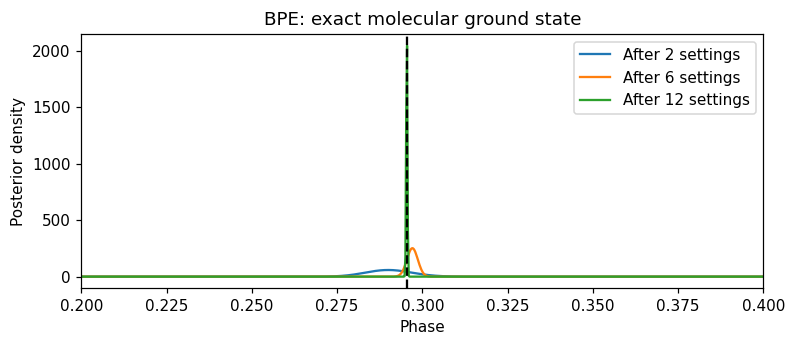

In [7]:
GRID = (np.arange(4096) + 0.5) / 4096  # 周期の端点を重複させない

def single_phase_model(phi, L, beta):
    return 0.5 * (1 + np.cos(TAU*L*phi + beta))

def bayes_update(grid, settings, true_probability, shots=256, seed=20261108):
    rng = np.random.default_rng(seed)
    logpost = np.zeros_like(grid)
    posteriors, data = [], []
    for L, beta in settings:
        true_p = float(np.clip(true_probability(L, beta), 0, 1))
        n0 = int(rng.binomial(shots, true_p))
        model_p = np.clip(single_phase_model(grid, L, beta), 1e-12, 1-1e-12)
        logpost += n0*np.log(model_p) + (shots-n0)*np.log1p(-model_p)
        logpost -= np.max(logpost)
        post = np.exp(logpost); post /= post.sum()
        posteriors.append(post)
        data.append((L, beta, shots, n0, true_p))
    return np.array(posteriors), data

def posterior_summary(grid, p):
    cdf = np.cumsum(p)
    lo, hi = np.interp([0.025, 0.975], cdf, grid)
    return {"MAP": float(grid[np.argmax(p)]), "mean": float(p @ grid),
            "equal_tail_95": (float(lo), float(hi))}


settings=[(L,beta) for L in [1,2,4,8,16,32] for beta in [0.,-np.pi/2]]
post_exact,data_exact=bayes_update(GRID,settings,lambda L,b:bpe_probability([1,0],L,b))
fig,ax=plt.subplots(figsize=(8,3))
for k in [1,5,11]: ax.plot(GRID,post_exact[k]*len(GRID),label=f"After {k+1} settings")
ax.axvline(PHASES[0],color="black",ls="--")
ax.set(xlabel="Phase",ylabel="Posterior density",xlim=(.2,.4),title="BPE: exact molecular ground state")
ax.legend(); plt.show()
summary=posterior_summary(GRID,post_exact[-1])
print(summary,"MAP total energy (Hartree):",phase_to_total(summary['MAP']))

### 4.1 発展時間と感度、周期の曖昧さ

$$\delta\theta=\delta E\,t,\qquad t=L\Delta t.$$
長時間ほど近いエネルギー差を大きな位相差に変えますが、候補は$2\pi/t$周期になります。
単一位相が正しいモデルで局所的に$\sigma_\phi\sim1/(2\pi L\sqrt R)$。
$L=1$でも余弦・正弦の両設定と十分なshotsで推定できます。
$L=32$固定では$[0,1)$に32個の同等な候補が残ります。
既知のエネルギー区間に制限すれば候補数は減りますが、一般には複数が残ります。

### 4.2 同じ総ショット数の3計画

元教材と同じく6段階、各段階2位相設定×256 shots、合計3,072 shots。
$L=1$固定、$1,2,4,8,16,32$、$L=32$固定を比較します。
総発展時間はそれぞれ3,072、32,256、98,304原子単位で、同じではありません。
全範囲・拡大図・等裾95%区間幅・64回の模擬実験のRMSEを表示します。
多峰分布のMAPは代表点にすぎず、区間幅もピーク間を含む値です。

Molecular BPE: target=0.29559450173785795, 256 shots/setting, 64 Monte Carlo trials
Plan          total shots  sum(R*L)  MAP        global 95% width  MAP error
L=1 only            3072      3072 0.292191          0.011355 -0.003404
Staged L            3072     32256 0.295456          0.000714 -0.000139
L=32 only           3072     98304 0.420609          0.968598 +0.125014
Repeated-experiment accuracy (first two identifiable plans):
Plan          circular RMSE  median global 95% width  interval coverage
L=1 only      0.003270                  0.011257              0.906
Staged L      0.000166                  0.000749              0.969
L=32 only: posterior mass in one alias cell around truth = 0.03124999999999999
L=32 only: min/max mass per 1/32-period cell = 0.031249999999995087 0.03125000000000237
L= 1: P(phi=0.137)=0.540795, P(phi+1/32)=0.442791
L=32: P(phi=0.137)=0.002524, P(phi+1/32)=0.002524
L=1 only energy RMSE (Hartree): 0.02054903319184087
Staged L energy RMSE (Hartree): 0.00

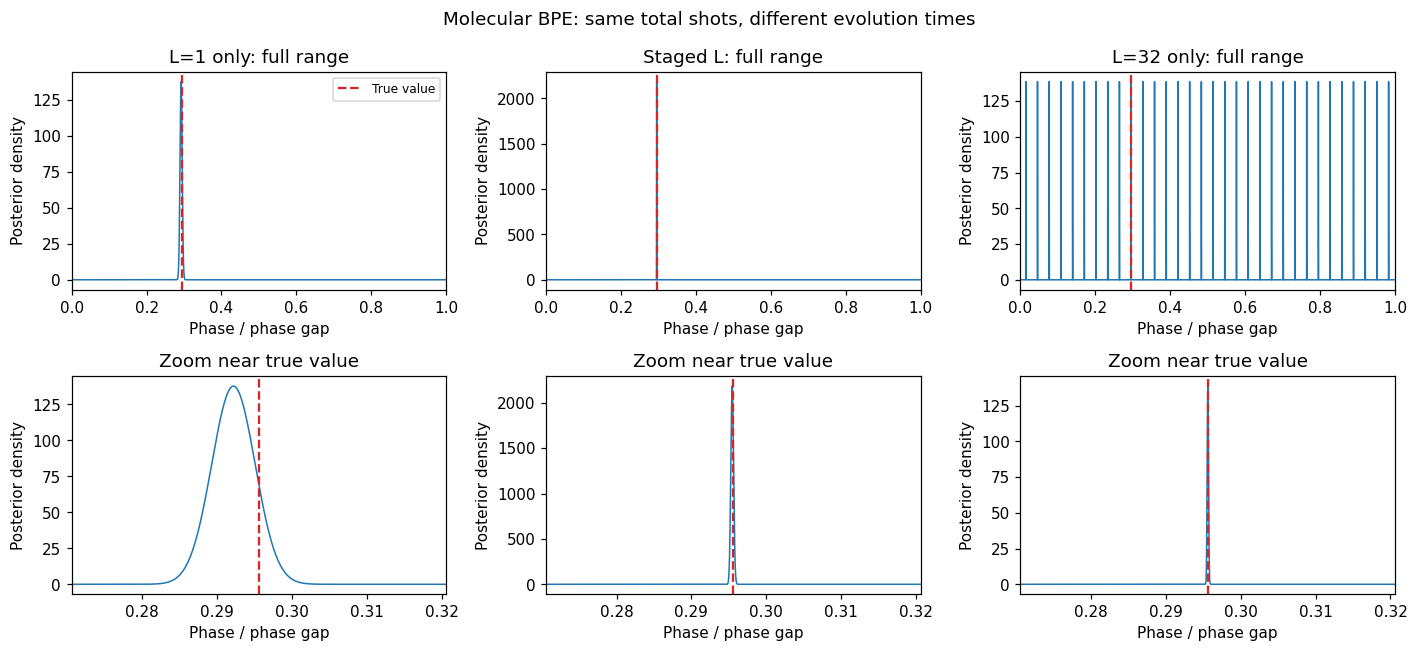

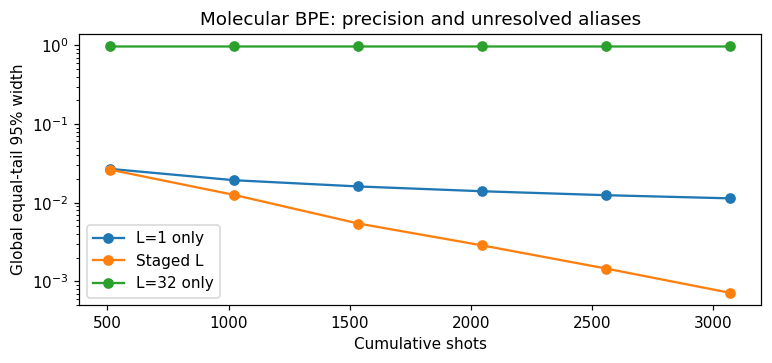

In [8]:
TIME_GRID = (np.arange(32768) + 0.5) / 32768
TIME_PLANS = {
    "L=1 only": [1, 1, 1, 1, 1, 1],
    "Staged L": [1, 2, 4, 8, 16, 32],
    "L=32 only": [32, 32, 32, 32, 32, 32],
}
TIME_BETAS = [np.pi/5, np.pi/5-np.pi/2]

def circular_error(estimate, target):
    return (np.asarray(estimate)-target+0.5) % 1 - 0.5

def compare_time_plans(true_probability, target, label, seed, shots=256, trials=64):
    grid = TIME_GRID
    results = {}
    print(f"{label}: target={target}, {shots} shots/setting, {trials} Monte Carlo trials")
    print("Plan          total shots  sum(R*L)  MAP        global 95% width  MAP error")
    for index, (name, lengths) in enumerate(TIME_PLANS.items()):
        plan = [(L, beta) for L in lengths for beta in TIME_BETAS]
        history, records = bayes_update(grid, plan, true_probability, shots=shots, seed=seed+index)
        summary = posterior_summary(grid, history[-1])
        widths = np.array([np.diff(posterior_summary(grid, p)["equal_tail_95"])[0]
                           for p in history[1::2]])
        results[name] = {"history": history, "records": records, "widths": widths,
                         "settings": plan, "summary": summary}
        error = circular_error(summary["MAP"], target)
        print(f"{name:13} {len(plan)*shots:10d} {shots*sum(L for L,b in plan):9d} "
              f"{summary['MAP']:.6f} {widths[-1]:17.6f} {error:+.6f}")

    fig, axes = plt.subplots(2, 3, figsize=(13, 6))
    for column, (name, result) in enumerate(results.items()):
        density = result["history"][-1] * len(grid)
        for row in [0, 1]:
            ax = axes[row, column]
            ax.plot(grid, density, lw=1)
            ax.axvline(target, color="C3", ls="--", label="True value")
            ax.set(xlabel="Phase / phase gap", ylabel="Posterior density")
        axes[0, column].set(xlim=(0, 1), title=name + ": full range")
        axes[1, column].set(xlim=(target-0.025, target+0.025), title="Zoom near true value")
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(label + ": same total shots, different evolution times", fontsize=12)
    plt.tight_layout(); plt.show()

    fig, ax = plt.subplots(figsize=(8, 3.2))
    cumulative_shots = 2*shots*np.arange(1, 7)
    for name, result in results.items():
        ax.semilogy(cumulative_shots, result["widths"], "o-", label=name)
    ax.set(xlabel="Cumulative shots", ylabel="Global equal-tail 95% width",
           title=label + ": precision and unresolved aliases")
    ax.legend(); plt.show()

    # 独立な模擬データを何組も生成し、1回の乱数例に依存しない精度を確認する。
    # ベイズ更新と同じ二項尤度を、行列積でまとめて評価する。
    print("Repeated-experiment accuracy (first two identifiable plans):")
    print("Plan          circular RMSE  median global 95% width  interval coverage")
    for index, name in enumerate(["L=1 only", "Staged L"]):
        plan = results[name]["settings"]
        probabilities = np.array([true_probability(L, beta) for L, beta in plan])
        rng = np.random.default_rng(seed + 100 + index)
        n0 = rng.binomial(shots, np.clip(probabilities, 0, 1), size=(trials, len(plan)))
        model = np.array([np.clip(single_phase_model(grid, L, beta), 1e-12, 1-1e-12)
                          for L, beta in plan])
        logpost = n0 @ np.log(model) + (shots-n0) @ np.log1p(-model)
        logpost -= logpost.max(axis=1, keepdims=True)
        posts = np.exp(logpost); posts /= posts.sum(axis=1, keepdims=True)
        estimates = grid[np.argmax(posts, axis=1)]
        intervals = np.array([posterior_summary(grid, p)["equal_tail_95"] for p in posts])
        rmse = np.sqrt(np.mean(circular_error(estimates, target)**2))
        coverage = np.mean((intervals[:, 0] <= target) & (target <= intervals[:, 1]))
        results[name]["rmse"] = float(rmse)
        print(f"{name:13} {rmse:.6f} {np.median(intervals[:,1]-intervals[:,0]):25.6f} {coverage:18.3f}")

    # L=32の周期性は、shotsや乱数では破れない。全32周期の確率質量を確認。
    long_post = results["L=32 only"]["history"][-1]
    mass_per_period = long_post.reshape(32, -1).sum(axis=1)
    assert np.allclose(mass_per_period, 1/32, atol=1e-9)
    near_true = np.abs(circular_error(grid, target)) < 1/64
    print("L=32 only: posterior mass in one alias cell around truth =", long_post[near_true].sum())
    print("L=32 only: min/max mass per 1/32-period cell =", mass_per_period.min(), mass_per_period.max())
    for L, beta in [(1, TIME_BETAS[0]), (32, TIME_BETAS[0])]:
        p = single_phase_model(0.137, L, beta)
        alias = single_phase_model(0.137+1/32, L, beta)
        print(f"L={L:2}: P(phi=0.137)={p:.6f}, P(phi+1/32)={alias:.6f}")
    return results


time_bpe=compare_time_plans(lambda L,b:bpe_probability([1,0],L,b),PHASES[0],"Molecular BPE",seed=510)
for name in ["L=1 only","Staged L"]:
    print(name,"energy RMSE (Hartree):",TAU*time_bpe[name]['rmse']/DT)

### 4.3 近似状態の信号と単一位相モデル

$$|\widetilde g\rangle=\sqrt{1-\eta}|S_0\rangle+\sqrt\eta|S_2\rangle.$$
真の確率は二つの余弦の重み付き和です。ここではHFに加え、差を見やすくするため$\eta=0.25$も使います。
ショットなしの曲線、模擬データによる事後分布、推定に使わない設定での予測を分けます。
**予想：** 事後分布が狭ければ、そのMAPは必ず固有位相でしょうか。

Exact S0 MAP 0.2950439453125 total energy -1.1338467877108176 held-out probability RMSE 0.00658607016720021
HF MAP 0.2979736328125 total energy -1.1522545571654454 held-out probability RMSE 0.02871590714130876
25% S2 MAP 0.2327880859375 total energy -0.7426816867999791 held-out probability RMSE 0.5209589802140838


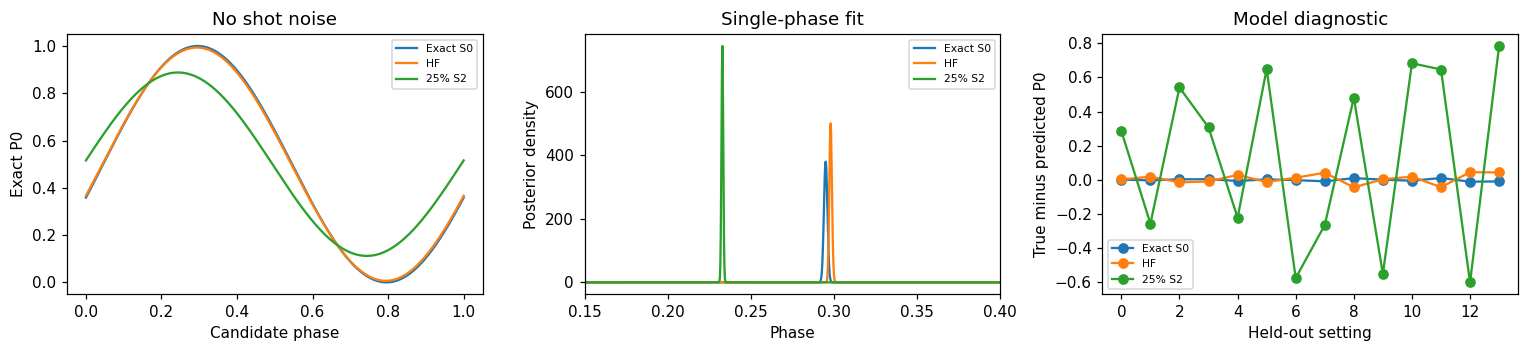

In [9]:
scan_settings=[(1,-TAU*v) for v in np.linspace(0,1,24,endpoint=False)]
fig,axes=plt.subplots(1,3,figsize=(14,3.3))
for eta,label in [(0,"Exact S0"),(HF_WEIGHTS[1],"HF"),(.25,"25% S2")]:
    weights=np.array([1-eta,eta])
    post,_=bayes_update(GRID,scan_settings,lambda L,b:bpe_probability(weights,L,b),shots=1024,seed=81)
    estimate=posterior_summary(GRID,post[-1])['MAP']
    axes[0].plot(candidates,bpe_probability(weights,1,-TAU*candidates),label=label)
    axes[1].plot(GRID,post[-1]*len(GRID),label=label)
    check=[(L,b) for L in range(2,9) for b in [0,-np.pi/2]]
    actual=np.array([bpe_probability(weights,L,b) for L,b in check])
    pred=np.array([single_phase_model(estimate,L,b) for L,b in check])
    axes[2].plot(actual-pred,"o-",label=label)
    print(label,"MAP",estimate,"total energy",phase_to_total(estimate),"held-out probability RMSE",np.sqrt(np.mean((actual-pred)**2)))
axes[0].set(xlabel="Candidate phase",ylabel="Exact P0",title="No shot noise")
axes[1].set(xlabel="Phase",ylabel="Posterior density",xlim=(.15,.4),title="Single-phase fit")
axes[2].set(xlabel="Held-out setting",ylabel="True minus predicted P0",title="Model diagnostic")
for ax in axes: ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
for eta in [0,.01,.1,.25]:
    state=np.sqrt(1-eta)*g+np.sqrt(eta)*e
    for L in [1,3,5]:
        assert np.isclose(ancilla_zero(ramsey_circuit(state,L,.31)),bpe_probability([1-eta,eta],L,.31),atol=ATOL)

### 演習4：精度と正しさ

コードの`eta`を0.01、0.1、0.25と変え、`shots=1024`を4096へ増やして比較してください。

1. 長時間固定の各ピークが狭くても、答えが一意でない理由は？
2. $L=2,4,8,16$だけならどんな曖昧さが残るか？
3. 近似状態でshotsを増やすと、モデルの不一致も消えるか？
<details><summary>解答例</summary>
1. すべての設定の尤度が$1/32$周期なので、一様事前分布で32候補の質量は等しいままです。
2. $1/2$周期の曖昧さが残ります。整数Lの最大公約数が周期を決めます。
3. 統計誤差は減っても、二周波数の信号は単一周波数にはなりません。信用区間は仮定したモデル内の不確かさです。
曲線のピーク、事後MAP、真の固有位相は異なる量であり、近似状態でも常に誤答になるという主張ではありません。
</details>

## 5．BPDE：S₀–S₂差を直接読む（Fig. 1B）

$$|\Psi\rangle=\frac{|0\rangle_a|S_0\rangle_s+|1\rangle_a|S_2\rangle_s}{\sqrt2}.$$
補助H → CNOT → 系$R_y(\theta)$で準備できます。
両枝に制御なし$U^L$をかけ、位相補正と逆準備を行うと
$$P_B(a=0)=\frac{1+\cos(2\pi L\Delta+\beta)}2
=\frac{1+\cos(\Delta E t-\beta)}2.$$
ギャップ候補$\varepsilon$には$\beta=\varepsilon t$。時間発展の制御は不要ですが、準備の制御は残ります。
$cI$と核間反発は共通位相なので差から消えます。

まず元教材に揃えて片側だけを近似します。
$$U_g=R_y(\theta),\quad U_e=R_y(\theta)R_y(2\arccos\sqrt\eta).$$
$\widetilde e=\sqrt\eta S_0+\sqrt{1-\eta}S_2$を作る**回路全体**を指定しています。
この規約では
$$P_B(a=0)=\tfrac12[1+\eta\cos\beta+(1-\eta)\cos(2\pi L\Delta+\beta)].$$

BPDE phase MAP 0.7398681640625
BPDE gap MAP (Hartree) 1.6344565294921507


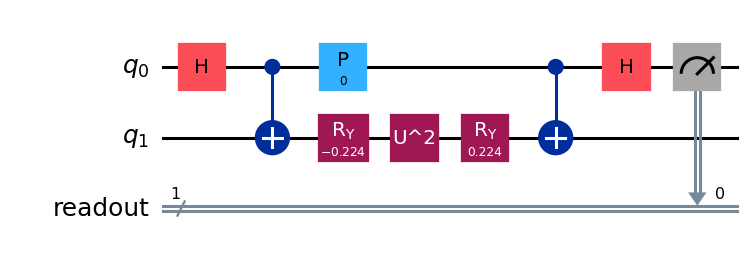

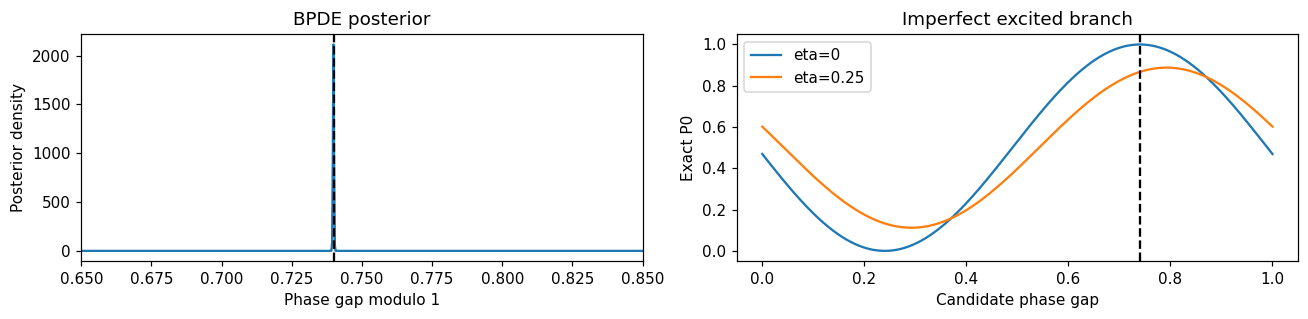

In [10]:
def preparation_b(eta=0., exact_cnot=False):
    qc=QuantumCircuit(2,name="W_B")
    qc.h(0)
    if exact_cnot:
        assert eta==0
        qc.cx(0,1)
    else:
        qc.cry(2*np.arccos(np.sqrt(eta)),0,1)
    qc.ry(theta,1)
    return qc

def bpde_circuit(eta=0.,L=1,beta=0.,exact_cnot=False,keep_constant=True):
    prep=preparation_b(eta,exact_cnot)
    qc=QuantumCircuit(2); qc.compose(prep,inplace=True)
    qc.append(evolution_gate(L,keep_constant),[1]); qc.p(beta,0)
    qc.compose(prep.inverse(),inplace=True)
    return qc

def bpde_probability(eta,L,beta):
    return .5*(1+eta*np.cos(beta)+(1-eta)*np.cos(TAU*L*GAP+beta))

# CNOTとcontrolled-Ry(pi)は |00> から同じ状態を準備するが、
# 他の入力への作用は異なる。厳密状態では同じ信号を確認する。
assert np.allclose(Statevector.from_instruction(preparation_b()).data,
                   Statevector.from_instruction(preparation_b(exact_cnot=True)).data,atol=ATOL)
draw_measured(bpde_circuit(L=2,exact_cnot=True),[0])
for eta in [0,.25,.7]:
    for L in [1,2,5]:
        for beta in [0,.31,-1.7]:
            assert np.isclose(ancilla_zero(bpde_circuit(eta,L,beta)),bpde_probability(eta,L,beta),atol=ATOL)
for L in [1,3]:
    assert np.isclose(ancilla_zero(bpde_circuit(L=L,exact_cnot=True)),bpde_probability(0,L,0),atol=ATOL)
    assert np.isclose(ancilla_zero(bpde_circuit(L=L,keep_constant=False)),bpde_probability(0,L,0),atol=ATOL)
post_gap,_=bayes_update(GRID,settings,lambda L,b:bpde_probability(0,L,b),seed=83)
fig,axes=plt.subplots(1,2,figsize=(12,3))
axes[0].plot(GRID,post_gap[-1]*len(GRID)); axes[0].axvline(GAP,color="black",ls="--")
axes[0].set(xlabel="Phase gap modulo 1",ylabel="Posterior density",xlim=(.65,.85),title="BPDE posterior")
for eta in [0,.25]: axes[1].plot(candidates,bpde_probability(eta,1,-TAU*candidates),label=f"eta={eta}")
axes[1].axvline(GAP,color="black",ls="--"); axes[1].legend()
axes[1].set(xlabel="Candidate phase gap",ylabel="Exact P0",title="Imperfect excited branch")
plt.tight_layout(); plt.show()
print("BPDE phase MAP",posterior_summary(GRID,post_gap[-1])['MAP'])
print("BPDE gap MAP (Hartree)",phase_to_gap(posterior_summary(GRID,post_gap[-1])['MAP']))

### 5.1 BPDEの時間計画

BPEと同じ総shotsで時間計画を比較します。位相差は約0.7402ですが、正のエネルギー差は約1.6324 Hartreeです。
同じ式の尤度でも、BPEとBPDEでは推定する物理量と回路が異なります。

Molecular BPDE: target=0.7402012359071664, 256 shots/setting, 64 Monte Carlo trials
Plan          total shots  sum(R*L)  MAP        global 95% width  MAP error
L=1 only            3072      3072 0.739059          0.011282 -0.001142
Staged L            3072     32256 0.739822          0.000755 -0.000379
L=32 only           3072     98304 0.365158          0.968598 -0.375043
Repeated-experiment accuracy (first two identifiable plans):
Plan          circular RMSE  median global 95% width  interval coverage
L=1 only      0.002604                  0.011250              0.969
Staged L      0.000187                  0.000740              0.969
L=32 only: posterior mass in one alias cell around truth = 0.031249999999999112
L=32 only: min/max mass per 1/32-period cell = 0.031249999999994747 0.031250000000004254
L= 1: P(phi=0.137)=0.540795, P(phi+1/32)=0.442791
L=32: P(phi=0.137)=0.002524, P(phi+1/32)=0.002524
L=1 only gap RMSE (Hartree): 0.01636192289067832
Staged L gap RMSE (Hartree): 0.001177

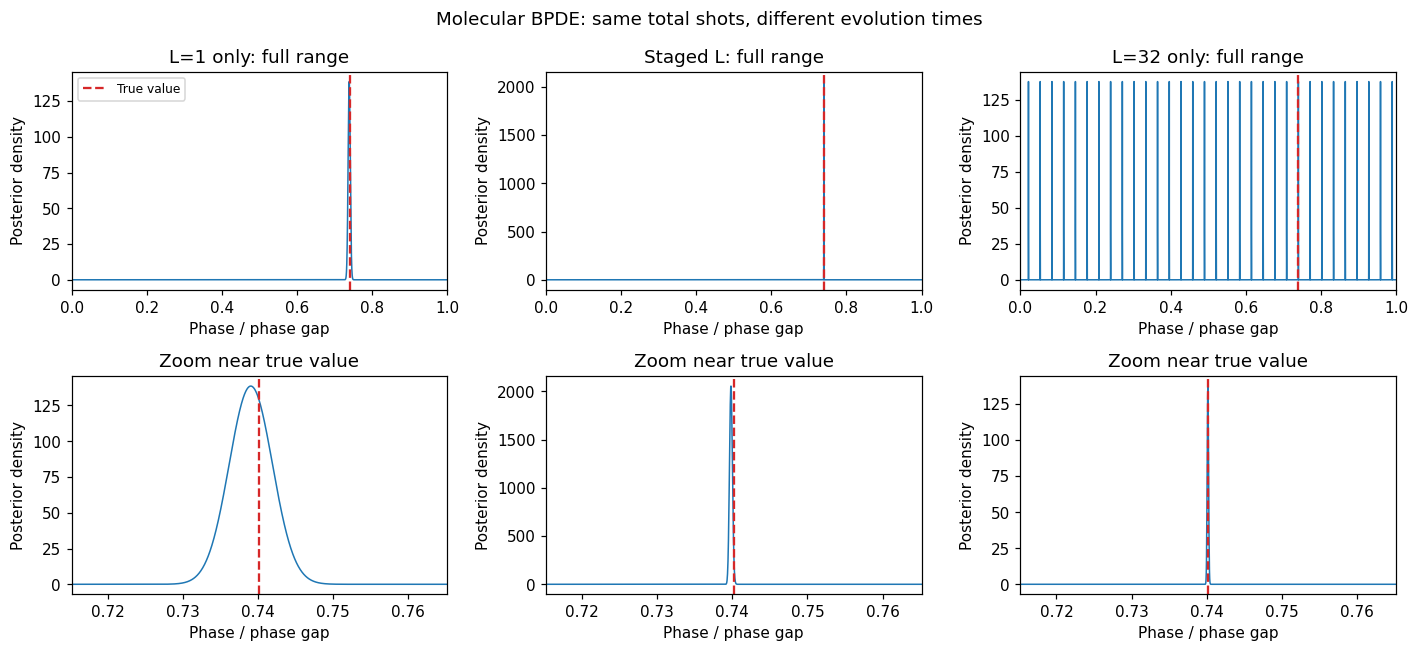

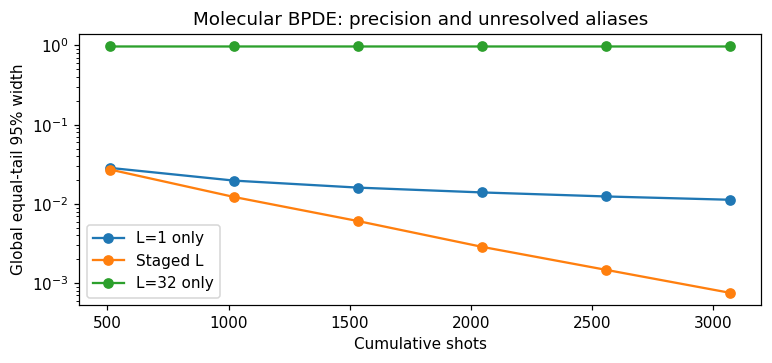

In [11]:
time_bpde=compare_time_plans(lambda L,b:bpde_probability(0,L,b),GAP,"Molecular BPDE",seed=610)
for name in ["L=1 only","Staged L"]:
    print(name,"gap RMSE (Hartree):",TAU*time_bpde[name]['rmse']/DT)

### 演習5：差を直接測る意味

$H\to H+dI$でBPEとBPDEの信号はどう変わるか。$\eta=1$なら何を測るか。
<details><summary>解答例</summary>
BPEの位相は$-d\Delta t/(2\pi)$ずれます。BPDEは共通位相が消えるため変わりません。
$\eta=1$は両枝がS₀となり、差0の信号です。差の直接測定でも、状態準備の混入は自動的には消えません。
</details>

## 6．Fig. 1Cへ：同じ状態でも補助だけでは読めない

$W|00\rangle=|\Psi\rangle$に対し、戻り確率は
$$P_C(\mathrm{全0})=|\langle\Psi|(P(\beta)\otimes U^L)|\Psi\rangle|^2.$$
同じ状態を準備する回路でも、他の入力への作用が異なれば、逆準備後の情報の出る場所は違います。
元教材と同じ説明用$W_C=W_B\,\mathrm{SWAP}$を使います。初期00にはSWAPが作用せず、準備状態は同じです。
しかし逆準備の最後にSWAPが入るので、厳密状態では補助0が常に1となり、全0だけが干渉を読みます。
このSWAPは原著の回路ではなく、読出し原理を示す例です。

近似状態では
$$A_g=\langle\widetilde g|U^L|\widetilde g\rangle,\quad
A_e=\langle\widetilde e|U^L|\widetilde e\rangle,\quad
P_C(\mathrm{全0})=\tfrac14|A_g+e^{i\beta}A_e|^2.$$
全0測定も近似準備状態への戻りであり、厳密固有状態への射影ではありません。

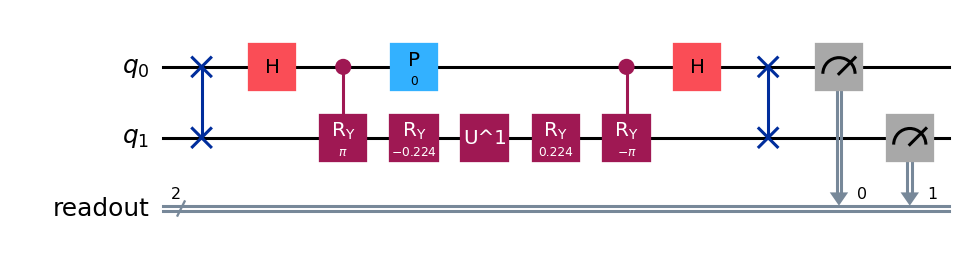

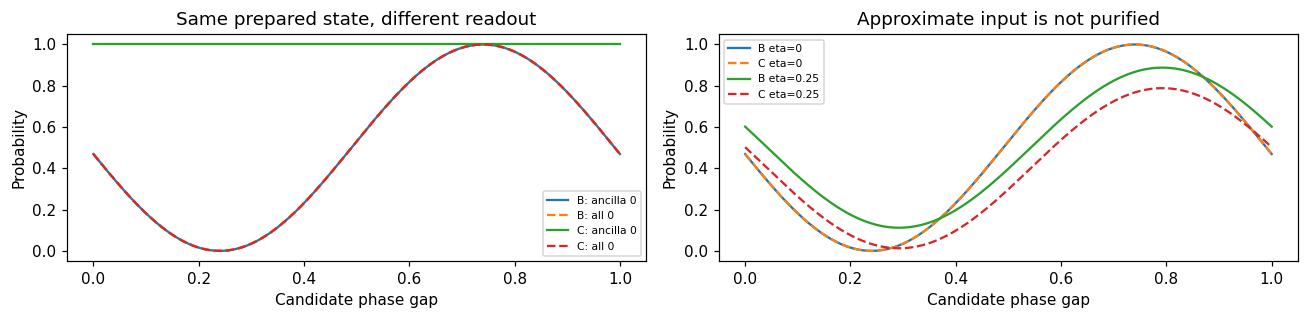

In [12]:
def preparation_c(eta=0.):
    qc=QuantumCircuit(2,name="W_C"); qc.swap(0,1)
    qc.compose(preparation_b(eta),inplace=True)
    return qc

def return_circuit(eta=0.,L=1,beta=0.,kind="C"):
    prep=preparation_c(eta) if kind=="C" else preparation_b(eta)
    qc=QuantumCircuit(2); qc.compose(prep,inplace=True)
    qc.append(evolution_gate(L),[1]); qc.p(beta,0)
    qc.compose(prep.inverse(),inplace=True)
    return qc

def readout(qc):
    sv=Statevector.from_instruction(qc)
    return float(sv.probabilities([0])[0]),float(abs(sv.data[0])**2)

def c_probability(eta,L,beta):
    ag=np.exp(1j*TAU*L*PHASES[0])
    ae=eta*ag+(1-eta)*np.exp(1j*TAU*L*PHASES[1])
    return .25*abs(ag+np.exp(1j*beta)*ae)**2

draw_measured(return_circuit(),[0,1])
assert np.allclose(Statevector.from_instruction(preparation_b()).data,Statevector.from_instruction(preparation_c()).data)
fig,axes=plt.subplots(1,2,figsize=(12,3))
for kind in ["B","C"]:
    vals=np.array([readout(return_circuit(beta=-TAU*v,kind=kind)) for v in candidates])
    axes[0].plot(candidates,vals[:,0],label=f"{kind}: ancilla 0")
    axes[0].plot(candidates,vals[:,1],ls="--",label=f"{kind}: all 0")
    if kind=="C": assert np.allclose(vals[:,0],1,atol=ATOL)
for eta in [0,.25]:
    axes[1].plot(candidates,bpde_probability(eta,1,-TAU*candidates),label=f"B eta={eta}")
    axes[1].plot(candidates,c_probability(eta,1,-TAU*candidates),ls="--",label=f"C eta={eta}")
for ax in axes: ax.set(xlabel="Candidate phase gap",ylabel="Probability"); ax.legend(fontsize=7)
axes[0].set_title("Same prepared state, different readout")
axes[1].set_title("Approximate input is not purified")
plt.tight_layout(); plt.show()
for eta in [0,.25,.7]:
    for L in [1,3,5]:
        for beta in [0,.31,-1.7]:
            for kind in ["B","C"]:
                assert np.isclose(readout(return_circuit(eta,L,beta,kind))[1],c_probability(eta,L,beta),atol=ATOL)

### 演習6：逆準備と読出し

同じ準備状態なら逆準備後の補助0確率も同じ、と言えるか。
<details><summary>解答例</summary>
言えません。時間発展で相対位相の変わった状態に対する逆準備の作用は、準備回路全体に依存します。
全0の戻り確率は準備状態だけで決まりますが、補助0はより広いランク2の部分空間への射影です。
</details>

## 7．全0測定のメリット：脱分極背景を拾いにくい

測定直前の全体脱分極$\rho'=(1-p)\rho+pI/2^n$では
$$P'(\Pi)=(1-p)P(\Pi)+p\,\mathrm{rank}(\Pi)/2^n.$$
補助0の背景は$p/2$、全0の背景は$p/2^n$。本編の系1＋補助1では$n=2$なので$p/4$です。
指数的に減るのは**固定pでの加算背景**であり、信号減衰$(1-p)$は残ります。
局所ゲートノイズや読み出し誤り全般の改善を保証しません。未使用量子ビットを足して改善する提案でもありません。
比較には同じB回路の出力を使います。Bでも全0を測れば同じ背景抑制があります。

Density-matrix readout: ancilla 0 0.5499999999999999 all 0 0.32499999999999996


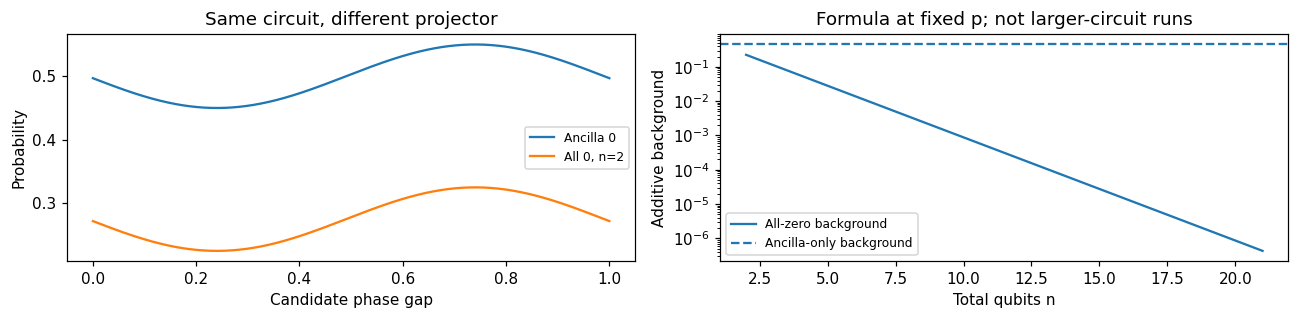

In [13]:
p_dep=.9
beta=-TAU*GAP
sv=Statevector.from_instruction(bpde_circuit(beta=beta))
density=DensityMatrix(sv).data
noisy=(1-p_dep)*density+p_dep*np.eye(4)/4
anc_projector=np.diag([1,0,1,0]); all_projector=np.diag([1,0,0,0])
a0=np.trace(anc_projector@noisy).real
all0=np.trace(all_projector@noisy).real
assert np.isclose(a0,1-p_dep+p_dep/2)
assert np.isclose(all0,1-p_dep+p_dep/4)
print("Density-matrix readout: ancilla 0",a0,"all 0",all0)
ideal=bpde_probability(0,1,-TAU*candidates)
fig,axes=plt.subplots(1,2,figsize=(12,3))
axes[0].plot(candidates,(1-p_dep)*ideal+p_dep/2,label="Ancilla 0")
axes[0].plot(candidates,(1-p_dep)*ideal+p_dep/4,label="All 0, n=2")
axes[0].set(xlabel="Candidate phase gap",ylabel="Probability",title="Same circuit, different projector")
ns=np.arange(2,22)
axes[1].semilogy(ns,p_dep/2.**ns,label="All-zero background")
axes[1].axhline(p_dep/2,ls="--",label="Ancilla-only background")
axes[1].set(xlabel="Total qubits n",ylabel="Additive background",title="Formula at fixed p; not larger-circuit runs")
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 演習7：背景が小さければ推定できるか？

$p=1$ならどうなるか。$p=0.9999$、10,000 shotsの最大信号カウントはいくつか。
<details><summary>解答例</summary>
$p=1$では候補依存性が消え、情報はありません。後者の最大信号カウントの期待値は1です。
背景抑制と有限shotsでの情報量は別問題です。
</details>

## 8．発展：有限分解能と結合伸長を分けて調べる

### 8.1 同じ分子でmだけ変える

元教材では最後に非格子位相へ進みました。本編の分子位相は初めから非格子なので、ここでm依存性を整理します。
**予想：** 厳密状態ならm=3でも誤差ゼロか。mを増やせばHFのS₂成分は消えるか。

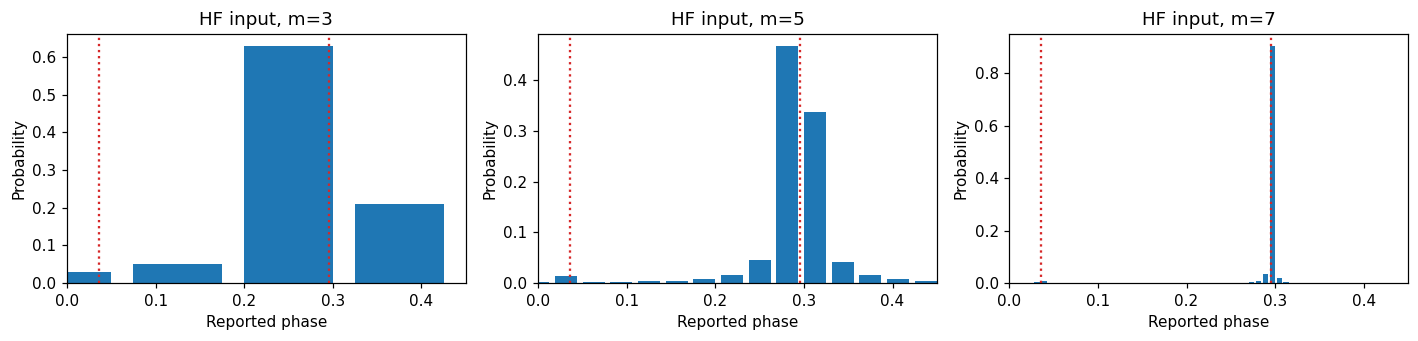

In [14]:
fig,axes=plt.subplots(1,3,figsize=(13,3.2))
for ax,m in zip(axes,[3,5,7]):
    pp=qpe_distribution(zero,m)
    expected=sum(w*qpe_formula(phi,m) for w,phi in zip(HF_WEIGHTS,PHASES))
    assert np.allclose(pp,expected,atol=ATOL)
    assert np.allclose(pp,iqpe_tree(zero,m)[0],atol=ATOL)
    grid=np.arange(2**m)/2**m
    ax.bar(grid,pp,width=.8/2**m)
    for phi in PHASES: ax.axvline(phi,color="C3",ls=":")
    ax.set(xlabel="Reported phase",ylabel="Probability",title=f"HF input, m={m}",xlim=(0,.45))
plt.tight_layout(); plt.show()

### 8.2 結合を伸ばす：同じ1量子ビットに電子相関が現れる

同じ基底・RHF分子軌道から生成した固定データを使います。付録Aですべて再生成して照合します。
距離ごとに論理0はその距離のRHF配置です。
同じ$R_y(\theta)$が、電子配置の混合と固有状態準備の両方を表します。
非相対論的・固定核・有限基底内の模型であり、S₂の正の全エネルギーを実在の束縛準位と同一視しません。

R=0.735: HF weight S0=0.987560, gap=1.632364 Hartree
R=1.5: HF weight S0=0.873688, gap=0.690957 Hartree
R=2.5: HF weight S0=0.594421, gap=0.574761 Hartree


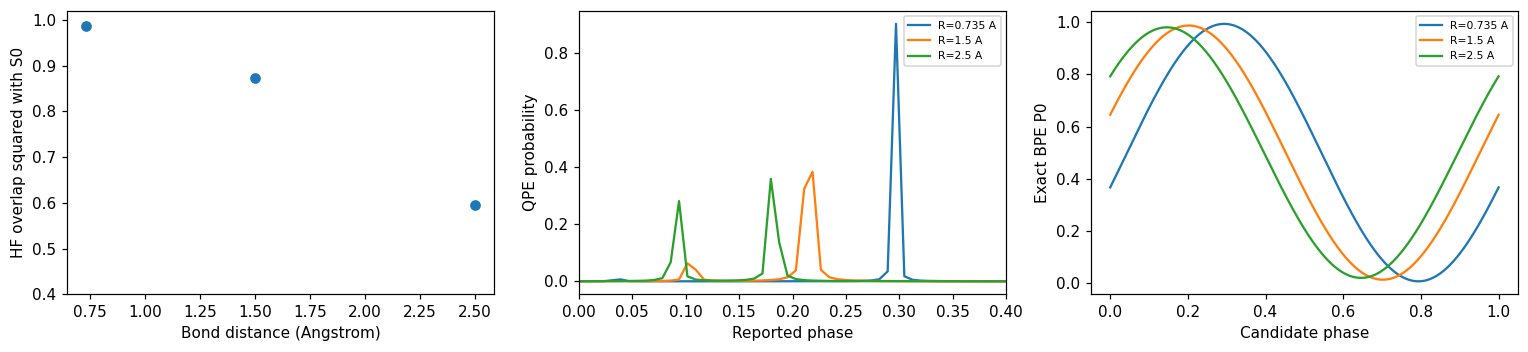

In [15]:
STRETCH_DATA=[
    (.735,H.copy(),ENUC),
    (1.5,np.array([[-1.2636583618743864,.22953593605970163],[.22953593605970163,-.7472531103259424]]),.35278480728),
    (2.5,np.array([[-.914614484091527,.28221004597538607],[.28221004597538607,-.8060756863879363]]),.21167088436800002),
]
fig,axes=plt.subplots(1,3,figsize=(14,3.3))
for distance,hh,enuc in STRETCH_DATA:
    ee,vv=np.linalg.eigh(hh)
    ww=abs(vv[0,:])**2
    phases=-ee*DT/TAU
    p=sum(w*qpe_formula(phi,7) for w,phi in zip(ww,phases))
    axes[0].plot(distance,ww[0],"o",color="C0")
    axes[1].plot(np.arange(128)/128,p,label=f"R={distance} A")
    fringe=.5*(1+np.real(np.dot(ww,np.exp(1j*TAU*phases))*np.exp(-1j*TAU*candidates)))
    axes[2].plot(candidates,fringe,label=f"R={distance} A")
    print(f"R={distance}: HF weight S0={ww[0]:.6f}, gap={ee[1]-ee[0]:.6f} Hartree")
axes[0].set(xlabel="Bond distance (Angstrom)",ylabel="HF overlap squared with S0",ylim=(.4,1.02))
axes[1].set(xlabel="Reported phase",ylabel="QPE probability",xlim=(0,.4))
axes[2].set(xlabel="Candidate phase",ylabel="Exact BPE P0")
axes[1].legend(fontsize=7); axes[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

### 演習8：何が変わり、何が残るか

8.1節の入力`zero`を`g`または`psi_mixed`へ変更し、同じmで出力を比較してください。

1. m増加でHFのS₂成分は消えるか。
2. 結合伸長でHFの重なりが減るのは、QPEのゲート誤差か。
3. 系1量子ビットでも電子相関を表せる理由は？
<details><summary>解答例</summary>
1. 消えません。位相分布は細かくなりますが、入力状態の成分の重みは残ります。
2. 違います。固定基底の厳密固有状態に対するHFという近似状態の重なりが変化します。
3. 一つの論理ビットが二つの多電子配置を表し、その重ね合わせが配置間の相関を表現するからです。
単一の物理電子のスピンを表す量子ビットではありません。
</details>

## 9．4方式とFig. 1Cを自分の言葉で説明する

| 方式 | 系以外の補助 | 系の扱い | 読み取る量 |
|---|---:|---|---|
| 逆QFT型QPE | m | 全回路で保持 | エネルギー位相のmビット分布 |
| iterative QPE | 1 | 各ビット後の条件付き状態を保持 | QPEと同じ分布 |
| この教材のBPE | 1 | 毎ショット再準備 | 単一位相モデルによるエネルギー推定 |
| Fig. 1B型BPDE | 1 | 毎ショット枝別準備 | S₂–S₀差、補助測定 |
| Fig. 1C型戻り測定 | 1 | 毎ショット重ね合わせ準備 | 準備状態への戻りを全0測定 |

QPE/IQPEの1回のmビット読出しは$\sum_r2^r=2^m-1$回の基本Uに相当します。
BPE/BPDEではshotsだけでなく$\sum RL$、最大L、制御Uの有無、準備・逆準備のコストも比較します。
本編は理想確率からの模擬測定で、同精度・同成功確率の最適資源比較ではありません。
本実装では長時間Uを角度の大きい回転として直接合成するため、$\sum RL$は物理的な回路ゲート数そのものではありません。

### 最終演習

1. 「補助1個だからIQPEとBPEは同じ」を訂正してください。
2. HFの期待エネルギー、QPEの固有エネルギー、単一位相モデルのMAPを区別してください。
3. なぜ本編ではS₀–S₁を測れないのでしょうか。
4. 全0測定のノイズ上の利点を条件付きで説明してください。
<details><summary>解答例</summary>
1. IQPEは系を条件付き状態のまま保持し、ここでのBPEは毎ショット再準備します。
2. 期待エネルギーは各固有エネルギーの重み付き平均。QPEは固有位相の分布。
MAPは選んだモデル・設定・データの下で事後確率が最大の候補で、常に固有値とは限りません。
3. S₁は外した不変ブロックにあります。対象の変更には保持する空間の変更が必要です。
4. 固定した測定直前の全体脱分極率pでは、全0の加算背景が$p/2^n$となります。信号減衰は残ります。
</details>

## 10．参考資料と教材の範囲

- [Qiskit Nature公式：Parity mappingと2量子ビット削減](https://qiskit-community.github.io/qiskit-nature/tutorials/06_qubit_mappers.html)
- [PySCF公式：Full-CI](https://pyscf.org/user/ci.html)
- [Dobšíček et al.：iterative QPE](https://arxiv.org/abs/quant-ph/0610214)
- [Wiebe–Granade：Efficient Bayesian Phase Estimation](https://arxiv.org/abs/1508.00869)
- [Sugisaki：Quantum Phase Difference Estimation](https://arxiv.org/abs/2307.09825)
- [Kanno et al.：Fig. 1、SI S1・S5](https://arxiv.org/html/2408.04946v4)

固定核H₂/STO-3G内での正確さと、実験値への正確さは別です。
本編の状態準備は小行列の既知の厳密解を利用します。大規模な未知分子でも同じ手間で準備できるという意味ではありません。
BPE/BPDEのグリッド更新、SWAPによるC読出し例は教材独自の実装です。

## 付録A．分子ハミルトニアンを積分から再生成する

ここだけPySCFを使います。Qiskit Natureは不要です。
RHF分子軌道積分から、16次元Fock空間で生成・消滅演算子を明示して
$$H=\sum_{pq\sigma}h_{pq}a^\dagger_{p\sigma}a_{q\sigma}
+\frac12\sum_{pqrs\sigma\tau}(pq|rs)
 a^\dagger_{p\sigma}a^\dagger_{r\tau}a_{s\tau}a_{q\sigma}$$
を作り、Parity基底への置換 → $p_1=1,p_3=0$固定 → 不変2×2ブロックの抽出を行います。
これはParity変換の定義を直接実装する小規模な参照計算です。
PySCFの独立なFull-CIと4固有値・スピンを照合して、S₀/S₂という同定も確認します。

**予想：** 2×2の二つの固有値を、全分子の最低二つの一重項と呼んでよいでしょうか。

In [16]:
import numpy as np
from pyscf import gto, scf, ao2mo, fci

def regenerate_h2(distance):
    mol = gto.M(atom=f'H 0 0 0; H 0 0 {distance}', basis='sto-3g', unit='Angstrom', verbose=0)
    mf = scf.RHF(mol).run()
    C = mf.mo_coeff
    h = C.T @ mf.get_hcore() @ C
    eri = ao2mo.restore(1, ao2mo.kernel(mol, C), 2)
    # モード順: alpha0, alpha1, beta0, beta1。|n3 n2 n1 n0>。
    annihilation = []
    for mode in range(4):
        a = np.zeros((16, 16))
        for n in range(16):
            if (n >> mode) & 1:
                a[n ^ (1 << mode), n] = (-1)**((n & ((1 << mode)-1)).bit_count())
        annihilation.append(a)
    Hf = np.zeros((16, 16))
    for p in range(2):
        for q in range(2):
            for spin in range(2):
                ap, aq = annihilation[p+2*spin], annihilation[q+2*spin]
                Hf += h[p,q] * ap.T @ aq
            for r in range(2):
                for s in range(2):
                    for sigma in range(2):
                        for tau in range(2):
                            ap, ar = annihilation[p+2*sigma], annihilation[r+2*tau]
                            ass, aq = annihilation[s+2*tau], annihilation[q+2*sigma]
                            Hf += 0.5*eri[p,q,r,s] * ap.T @ ar.T @ ass @ aq
    # Parity変換 b_j = (n_0+...+n_j) mod 2 は基底の置換。
    P = np.zeros((16,16))
    for n in range(16):
        b = sum(((n & ((1 << (j+1))-1)).bit_count() % 2) << j for j in range(4))
        P[b,n] = 1
    Hp = P @ Hf @ P.T
    # N_alpha=N_beta=1: b1=1, b3=0。残る配列順は |b2 b0>。
    indices = [b0 + 2 + 4*b2 for b2 in range(2) for b0 in range(2)]
    H2 = Hp[np.ix_(indices,indices)]
    block = H2[np.ix_([1,2],[1,2])]
    energies, vectors = np.linalg.eigh(block)
    full_e, full_ci = fci.FCI(mf).kernel(nroots=4)
    spins = np.array([fci.spin_op.spin_square(ci, 2, (1,1))[0] for ci in full_ci])
    assert np.allclose(np.linalg.eigvalsh(H2)+mol.energy_nuc(), full_e, atol=1e-9)
    assert np.allclose(energies+mol.energy_nuc(), full_e[[0,3]], atol=1e-9)
    assert np.allclose(spins, [0,2,0,0], atol=1e-8)
    return H2, block, mol.energy_nuc(), full_e, spins


import pyscf
print("PySCF",pyscf.__version__)
for distance,hh,enuc in STRETCH_DATA:
    h2,block,nuclear,full_e,spins=regenerate_h2(distance)
    assert np.allclose(block,hh,atol=1e-9)
    assert np.isclose(nuclear,enuc,atol=1e-9)
    # 抽出した空間と外側の結合がないことも確認。
    assert np.allclose(h2[np.ix_([1,2],[0,3])],0,atol=1e-9)
    print("R =",distance,"Angstrom; full total energies:",full_e,"S^2:",spins)
    if distance==.735:
        print("Parity 2-qubit H =\n",h2)
        print("Retained logical H =\n",block)
print("All three molecular fixtures match regenerated integrals and Full-CI.")

PySCF 2.13.1
R = 0.735 Angstrom; full total energies: [-1.13730604 -0.52461556 -0.16275316  0.49505774] S^2: [0. 2. 0. 0.]
Parity 2-qubit H =
 [[-1.06365335  0.          0.          0.1809312 ]
 [ 0.         -1.83696799  0.1809312   0.        ]
 [ 0.          0.1809312  -0.24521829  0.        ]
 [ 0.1809312   0.          0.         -1.06365335]]
Retained logical H =
 [[-1.83696799  0.1809312 ]
 [ 0.1809312  -0.24521829]]
R = 1.5 Angstrom; full total energies: [-0.99814935 -0.89058478 -0.43151291 -0.3071925 ] S^2: [0. 2. 0. 0.]
R = 2.5 Angstrom; full total energies: [-0.93605492 -0.93163909 -0.36721899 -0.36129348] S^2: [0. 2. 0. 0.]
All three molecular fixtures match regenerated integrals and Full-CI.


### 付録演習：削減しても残るもの、失うもの

<details><summary>解答例</summary>
抽出したブロックの二つの固有値は全分子のS₀とS₂です。S₁と最低三重項は別ブロックです。
4スピン軌道から既知のParityを固定する削減と、さらに一方の不変空間を選ぶ操作は別段階です。
保持した空間内では近似なしですが、外した状態を本編の系1ビットで扱うことはできません。
</details>

In [17]:
assert np.allclose(p_qpe,p_iqpe,atol=ATOL)
assert abs(posterior_summary(GRID,post_exact[-1])["MAP"]-PHASES[0])<.005
assert abs(posterior_summary(GRID,post_gap[-1])["MAP"]-GAP)<.005
assert np.allclose(E+ENUC,[-1.1373060357534004,.4950577416181072],atol=1e-9)
assert np.isclose(ENERGY_GAP,1.6323637773715076,atol=1e-9)
print("全セル完了：分子積分・Full-CI・縮約・厳密発展・QFT・QPE/IQPE・B/C確率・脱分極を照合しました。")

全セル完了：分子積分・Full-CI・縮約・厳密発展・QFT・QPE/IQPE・B/C確率・脱分極を照合しました。
